# Exoplanet Transit and Orbital Analysis
### Characterizing an Exoplanet Candidate Using TESS Light-Curve Data

**Danessa Ruff**  
Michigan State University | Astrophysics  
*Independent extension of AST 208 coursework*

---

## Overview

This project uses TESS light-curve data to investigate a transiting exoplanet candidate. I analyzed repeated decreases in stellar brightness to estimate the planet's orbital period, transit depth, duration, radius, and orbital distance.

I also explored the system's orbital geometry and modeled gravitational motion using differential equations and numerical integration.

## Research Question

What can transit observations tell us about an exoplanet's physical properties and orbital motion?

## Methods

- Light-curve analysis and transit detection
- Orbital period estimation
- Transit depth and duration measurements
- Planetary radius and orbital distance calculations
- Orbital geometry and numerical modeling using the Runge–Kutta method

## Data

The analysis uses `TESSB_lc.dat`, a light-curve dataset provided through AST 208 coursework at Michigan State University. The file contains observation times in Barycentric Julian Date, normalized flux, and flux uncertainties.

The provided flux is already detrended, so only minimal additional normalization is applied.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import differential_evolution
from scipy.ndimage import median_filter

plt.rcParams["figure.figsize"] = (10, 5) #plot width for easy viewing
plt.rcParams["axes.grid"] = True #grid lines default

## 1. Physical Equations

### Transit Depth

The fractional decrease in stellar brightness during a transit is approximately

$$\delta = \left(\frac{R_p}{R_{\star}}\right)^2$$

The planet's radius can then be estimated using

$$R_p = R_{\star}\sqrt{\delta}$$

This approximation assumes a small planet relative to the star and ignores limb darkening.

### Transit Timing

For a planet with a constant orbital period, the transit centers follow

$$t_n = t_0 + nP$$

where:
- $t_n$ is the time of the nth transit
- $t_0$ is a reference transit center
- $P$ is the orbital period

### Kepler's Third Law

Assuming the planet's mass is negligible compared with the star's mass,

$$a^3 = \frac{GM_{\star}P^2}{4\pi^2}$$

Solving for the orbital distance gives

$$a = \left(\frac{GM_{\star}P^2}{4\pi^2}\right)^{1/3}$$

### Orbital Geometry

For a circular orbit, the position of the planet can be described by

$$\mathbf{r}(t) = \langle x(t), y(t) \rangle$$

where

$$x(t) = a\cos(\omega t)$$

$$y(t) = a\sin(\omega t)$$

and

$$\omega = \frac{2\pi}{P}$$

### Projected Separation

For an orbital inclination $i$, the sky-plane separation is

$$d(t) = \sqrt{x(t)^2 + (y(t)\cos i)^2}$$

A transit is possible when the projected separation is smaller than the combined stellar and planetary radii.

### Gravitational Motion

The planet's motion under the star's gravity is described by

$$\frac{d^2\mathbf{r}}{dt^2} = -\frac{GM_{\star}}{r^3}\mathbf{r}$$

In component form,

$$\frac{dx}{dt} = v_x$$

$$\frac{dy}{dt} = v_y$$

$$\frac{dv_x}{dt} = -\frac{GM_{\star}x}{r^3}$$

$$\frac{dv_y}{dt} = -\frac{GM_{\star}y}{r^3}$$

I use a fourth-order Runge–Kutta (RK4) method to numerically solve these equations and explore the planet's orbital motion.

In [16]:
#loads light curve data
data = np.loadtxt("TESSB_lc.dat")

time_bjd = data[:, 0]
flux = data[:, 1]
flux_err = data[:, 2]

#start time at zero to make the days easier to work with
time = time_bjd - time_bjd[0]

print("Observations:", len(time))
print("Time span:", round(time.max() - time.min(), 5), "days")
print("Median cadence:", round(np.median(np.diff(time)), 6), "days")
print("Median flux error:", round(np.median(flux_err), 6))

Observations: 1709
Time span: 51.62985 days
Median cadence: 0.020833 days
Median flux error: 0.000329


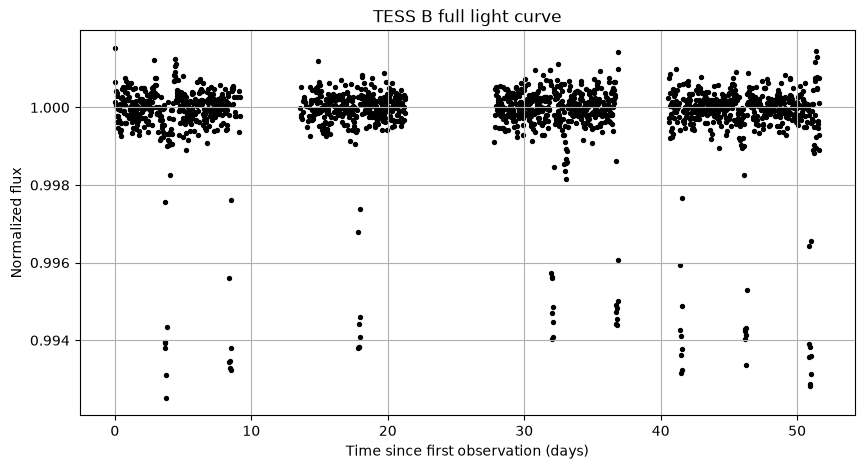

In [5]:
#visual look at full light curve
plt.figure()
plt.scatter(time, flux, s=8, color="black")
plt.xlabel("Time since first observation (days)")
plt.ylabel("Normalized flux")
plt.title("TESS B full light curve")
plt.show()

## 2. Light normalization

The file already contains detrended normalized flux, so the baseline should be near 1.  
However, a mild median-filter normalization is still useful for stabilizing the transit search against small local offsets.

This is **not** a heavy detrending procedure. It is only a light correction applied to an already detrended light curve.

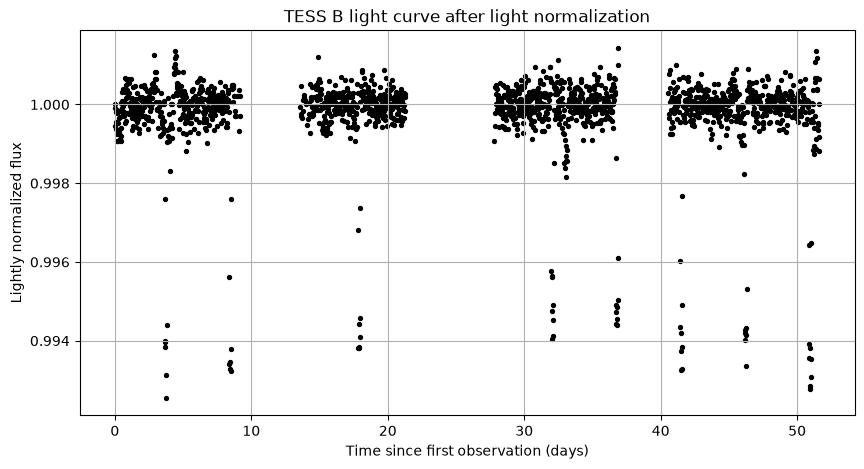

In [6]:
trend = median_filter(flux, size=101, mode="nearest")
flux_norm = flux / trend * np.median(trend)

plt.figure()
plt.scatter(time, flux_norm, s=8, color="black")
plt.xlabel("Time since first observation (days)")
plt.ylabel("Lightly normalized flux")
plt.title("TESS B light curve after light normalization")
plt.show()

## 3. Detect candidate transits

The transit signal appears as repeated dips in the light curve.
To get an initial estimate of the orbital period, I first search for deep local minima in the normalized flux.

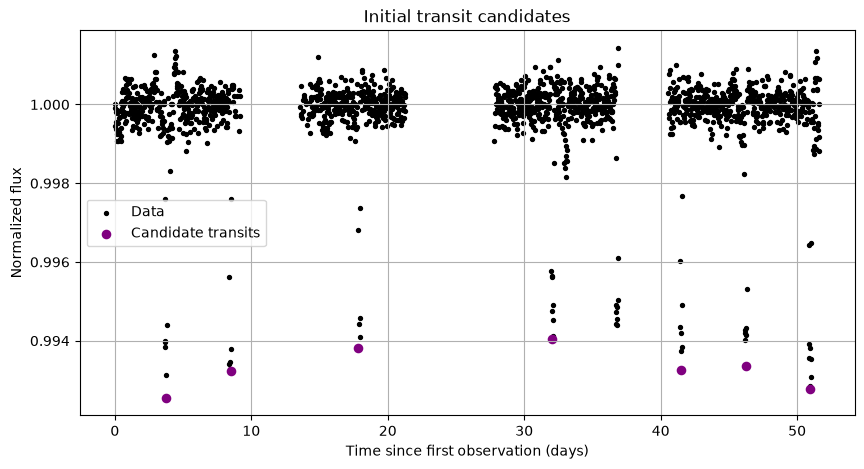

Initial candidate transit times (days):
[ 3.750171  8.479551 17.834171 32.046695 41.504992 46.234096 50.963189]


In [7]:
#initial transit search on inverted light curve
cadence = np.median(np.diff(time))
min_separation_days = 3.0
min_separation_points = int(min_separation_days / cadence)

peaks, peak_props = find_peaks(1.0 - flux_norm, prominence=0.002, distance=min_separation_points)

candidate_times = time[peaks]
candidate_fluxes = flux_norm[peaks]

plt.figure()
plt.scatter(time, flux_norm, s=8, color="black", label="Data")
plt.scatter(candidate_times, candidate_fluxes, s=35, color="Purple", label="Candidate transits")
plt.xlabel("Time since first observation (days)")
plt.ylabel("Normalized flux")
plt.title("Initial transit candidates")
plt.legend()
plt.show()

print("Initial candidate transit times (days):")
print(np.round(candidate_times, 6))

## 4. Refine the transit centers

To improve the transit timing measurements, each candidate dip is re-centered by fitting a quadratic curve to a few points around the local minimum.
This is not a full physical transit model, but it provides a better estimate of the time of minimum light than simply taking the lowest point.

In [8]:
def refine_transit_center_quadratic(t_window, f_window, points_each_side=2):
    imin = np.argmin(f_window)
    i0 = max(0, imin - points_each_side)
    i1 = min(len(t_window), imin + points_each_side + 1)

    t_fit = t_window[i0:i1]
    f_fit = f_window[i0:i1]

    if len(t_fit) < 3:
        return t_window[imin]

    a2, a1, a0 = np.polyfit(t_fit, f_fit, 2)
    if a2 <= 0:
        return t_window[imin]

    t_vertex = -a1 / (2 * a2)

    #if the fitted vertex falls outside local fitting window, fall back to minimum point
    if (t_vertex < t_fit.min()) or (t_vertex > t_fit.max()):
        return t_window[imin]

    return t_vertex


refined_centers = []
for t_guess in candidate_times:
    local = np.abs(time - t_guess) < 0.25
    refined_centers.append(refine_transit_center_quadratic(time[local], flux_norm[local]))

refined_centers = np.array(refined_centers)
print("Refined transit centers (days):")
print(np.round(refined_centers, 6))

Refined transit centers (days):
[ 3.748335  8.450155 17.866416 32.046695 41.514381 46.229221 50.964723]


## 5. Fit the orbital period from the transit centers

The observed transit centers follow

`t_n = t0 + nP`

To fit this relation, each transit is assigned an integer cycle number based on the approximate spacing between events.

Best-fit orbital period: 4.722675 ± 0.001883 days
Reference transit center t0: 3.725852 ± 0.012141 days


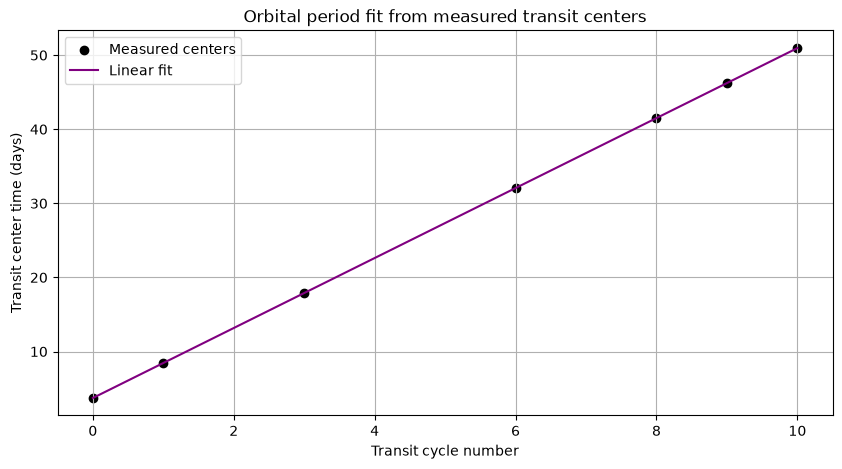

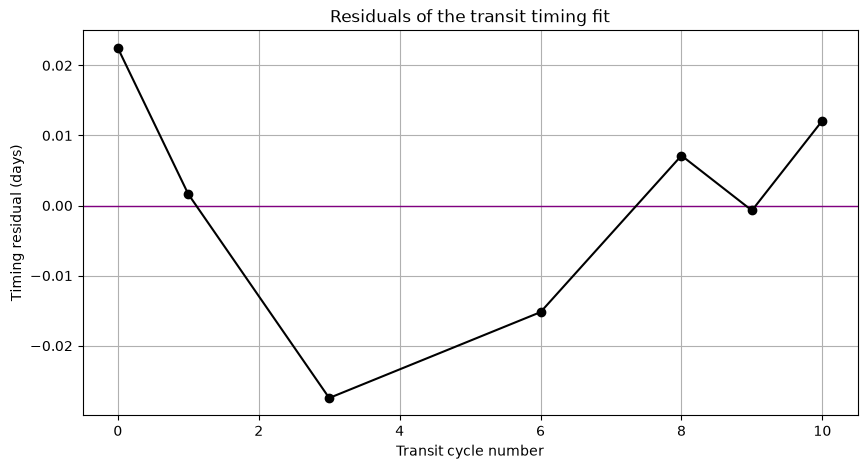

In [14]:
#assigns cycle numbers from the observed spacing
period_guess = 4.72

cycle_numbers = [0]
for dt in np.diff(refined_centers):
    cycles = round(dt / period_guess)
    cycle_numbers.append(cycle_numbers[-1] + cycles)

#linear fit: t_n = t0 + nP
coeff = np.polyfit(cycle_numbers, refined_centers, 1)
period_days = coeff[0]
t0_days = coeff[1]

predicted_centers = np.polyval(coeff, cycle_numbers)
timing_residuals = refined_centers - predicted_centers

#standard error from linear regression
X = np.vstack([cycle_numbers, np.ones_like(cycle_numbers)]).T
cov = np.linalg.inv(X.T @ X) * np.sum(timing_residuals**2) / (len(cycle_numbers) - 2)
period_err_days = np.sqrt(cov[0, 0])
t0_err_days = np.sqrt(cov[1, 1])

print(f"Best-fit orbital period: {period_days:.6f} ± {period_err_days:.6f} days")
print(f"Reference transit center t0: {t0_days:.6f} ± {t0_err_days:.6f} days")

plt.figure()
plt.scatter(cycle_numbers, refined_centers, color="black", label="Measured centers")
plt.plot(cycle_numbers, predicted_centers, color="purple", label="Linear fit")
plt.xlabel("Transit cycle number")
plt.ylabel("Transit center time (days)")
plt.title("Orbital period fit from measured transit centers")
plt.legend()
plt.show()

plt.figure()
plt.axhline(0, color="purple", lw=1)
plt.plot(cycle_numbers, timing_residuals, "o-", color="black")
plt.xlabel("Transit cycle number")
plt.ylabel("Timing residual (days)")
plt.title("Residuals of the transit timing fit")
plt.show()

## 6. Fold the light curve on the measured orbital period

Folding the light curve places all transits on top of one another so that the repeated signal can be studied more clearly.

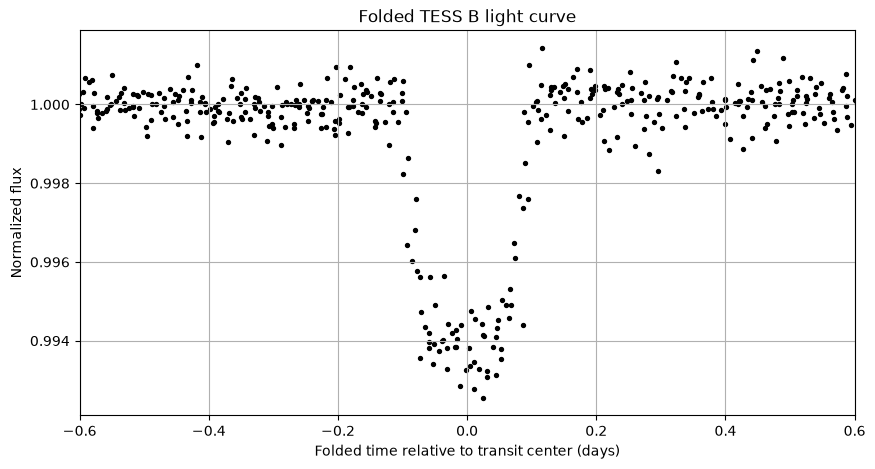

In [10]:
phase = ((time - t0_days + 0.5 * period_days) % period_days) - 0.5 * period_days

plt.figure()
plt.scatter(phase, flux_norm, s=8, color="black")
plt.xlim(-0.6, 0.6)
plt.xlabel("Folded time relative to transit center (days)")
plt.ylabel("Normalized flux")
plt.title("Folded TESS B light curve")
plt.show()

## 7. Box-transit characterization

A simplified box-shaped transit model is used to estimate:
- transit depth
- transit duration
- an optimized transit center and period

This is still a simplified model because it ignores limb darkening and detailed ingress/egress structure, but it is appropriate for a first-pass physical characterization.

In [15]:
def weighted_box_model(time_array, flux_array, err_array, P, t0, duration):
    phase_local = ((time_array - t0 + 0.5 * P) % P) - 0.5 * P
    in_transit = np.abs(phase_local) < duration / 2

    if in_transit.sum() < 5 or (~in_transit).sum() < 5:
        return np.nan, np.inf, in_transit, None, None

    weights = 1.0 / err_array**2
    out_flux = np.average(flux_array[~in_transit], weights=weights[~in_transit])
    in_flux = np.average(flux_array[in_transit], weights=weights[in_transit])

    depth = out_flux - in_flux

    model = np.full_like(flux_array, out_flux)
    model[in_transit] = out_flux - depth

    chi2 = np.sum(((flux_array - model) / err_array)**2)
    return depth, chi2, in_transit, model, phase_local


def objective_box(params):
    P, t0, duration = params
    _, chi2, _, _, _ = weighted_box_model(time, flux_norm, flux_err, P, t0, duration)
    return chi2


result = differential_evolution(objective_box, bounds=[(4.70, 4.74), (3.68, 3.80), (0.12, 0.25)], seed=1, maxiter=25, popsize=12, polish=True)

P_box, t0_box, duration_days = result.x
depth_frac, chi2_box, in_transit_mask, box_model_flux, phase_box = weighted_box_model(
    time, flux_norm, flux_err, P_box, t0_box, duration_days)

print(f"Optimized box-model period: {P_box:.6f} days")
print(f"Optimized box-model t0: {t0_box:.6f} days")
print(f"Transit depth: {depth_frac:.6f}")
print(f"Transit duration: {duration_days:.6f} days")

Optimized box-model period: 4.721015 days
Optimized box-model t0: 3.731266 days
Transit depth: 0.005681
Transit duration: 0.169138 days


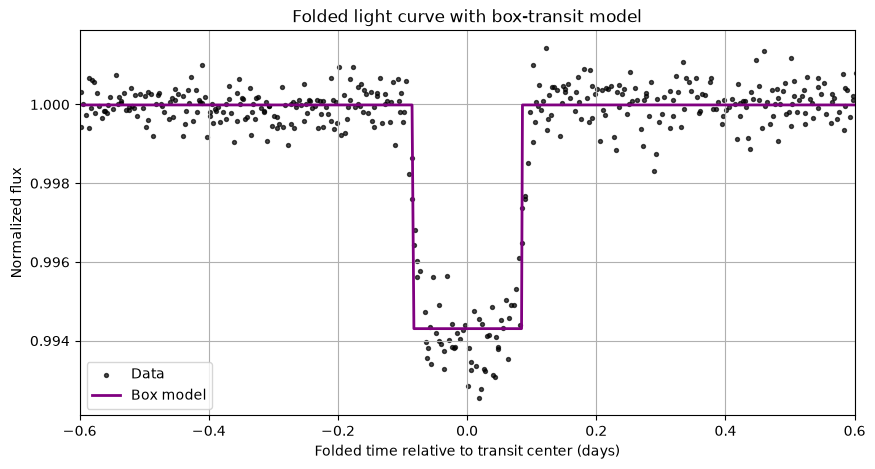

In [12]:
#plots folded light curve with box model
sort_idx = np.argsort(phase_box)

plt.figure()
plt.scatter(phase_box, flux_norm, s=8, color="black", alpha=0.7, label="Data")
plt.plot(phase_box[sort_idx], box_model_flux[sort_idx], color="purple", lw=2, label="Box model")
plt.xlim(-0.6, 0.6)
plt.xlabel("Folded time relative to transit center (days)")
plt.ylabel("Normalized flux")
plt.title("Folded light curve with box-transit model")
plt.legend()
plt.show()

## 8. Measure individual transit depths and durations

I measured the depth and duration of each transit separately to estimate how much these measurements vary between events.
The final quoted depth and duration are based on the mean across measured transit events, with uncertainty taken from the standard error of the mean.

In [18]:
def estimate_single_transit_properties(time_array, flux_array, center_guess):
    window = np.abs(time_array - center_guess) < 0.4
    t_local = time_array[window]
    f_local = flux_array[window]

    if len(t_local) < 10:
        return np.nan, np.nan, np.nan

    #refines transit center
    center_local = refine_transit_center_quadratic(t_local, f_local, points_each_side=2)

    dt = t_local - center_local

    #estimates out-of-transit baseline and in-transit level
    out_region = (np.abs(dt) > 0.18) & (np.abs(dt) < 0.35)
    in_region = np.abs(dt) < 0.10

    if out_region.sum() < 5 or in_region.sum() < 5:
        return center_local, np.nan, np.nan

    baseline = np.median(f_local[out_region])
    transit_floor = np.median(f_local[in_region])
    depth = baseline - transit_floor

    #half-depth duration estimate by linear interpolation
    target = baseline - 0.5 * depth
    order = np.argsort(dt)
    dt = dt[order]
    ff = f_local[order]
    vals = ff - target

    left_cross = np.nan
    right_cross = np.nan

    for j in range(len(dt) - 1):
        if dt[j] < 0 and vals[j] * vals[j + 1] <= 0:
            left_cross = dt[j] - vals[j] * (dt[j + 1] - dt[j]) / (vals[j + 1] - vals[j])

    for j in range(len(dt) - 1):
        if dt[j] >= 0 and vals[j] * vals[j + 1] <= 0:
            right_cross = dt[j] - vals[j] * (dt[j + 1] - dt[j]) / (vals[j + 1] - vals[j])
            break

    duration = right_cross - left_cross if np.isfinite(left_cross) and np.isfinite(right_cross) else np.nan
    return center_local, depth, duration


#expected transit centers from period fit
n_max = int((time.max() - t0_days) / period_days) + 1
expected_centers = t0_days + np.arange(n_max + 1) * period_days
expected_centers = expected_centers[(expected_centers >= time.min()) & (expected_centers <= time.max())]

single_centers = []
single_depths = []
single_durations = []

for center_guess in expected_centers:
    c, d, dur = estimate_single_transit_properties(time, flux_norm, center_guess)
    if np.isfinite(c) and np.isfinite(d) and np.isfinite(dur):
        single_centers.append(c)
        single_depths.append(d)
        single_durations.append(dur)

single_centers = np.array(single_centers)
single_depths = np.array(single_depths)
single_durations = np.array(single_durations)

depth_mean = np.mean(single_depths)
depth_err = np.std(single_depths, ddof=1) / np.sqrt(len(single_depths))

duration_mean_days = np.mean(single_durations)
duration_err_days = np.std(single_durations, ddof=1) / np.sqrt(len(single_durations))

transit_table = pd.DataFrame({"transit_center_days": single_centers, "depth_fraction": single_depths,"duration_days": single_durations})
transit_table

Individual transit durations (hours): [4.128 3.949 4.005 4.035 4.001 4.071 3.927 4.103]


,transit_center_days,depth_fraction,duration_days
0,3.748335,0.005494,0.172002
1,8.450155,0.006456,0.164537
2,17.866416,0.005766,0.166864
3,32.046695,0.005143,0.168119
4,36.775788,0.005325,0.166712
5,41.514381,0.005793,0.169608
6,46.229221,0.005723,0.163622
7,50.964723,0.006440,0.170951


In [33]:
print(f"Final adopted period: {period_days:.6f} ± {period_err_days:.6f} days")
print(f"Final adopted depth: {depth_mean:.6f} ± {depth_err:.6f}")
print(f"Final adopted duration: {duration_mean_days:.6f} ± {duration_err_days:.6f} days")
print(f"Final adopted duration: {duration_mean_days * 24:.3f} ± {duration_err_days * 24:.3f} hours")

Final adopted period: 4.722675 ± 0.001883 days
Final adopted depth: 0.005767 ± 0.000168
Final adopted duration: 0.167802 ± 0.001045 days
Final adopted duration: 4.027 ± 0.025 hours


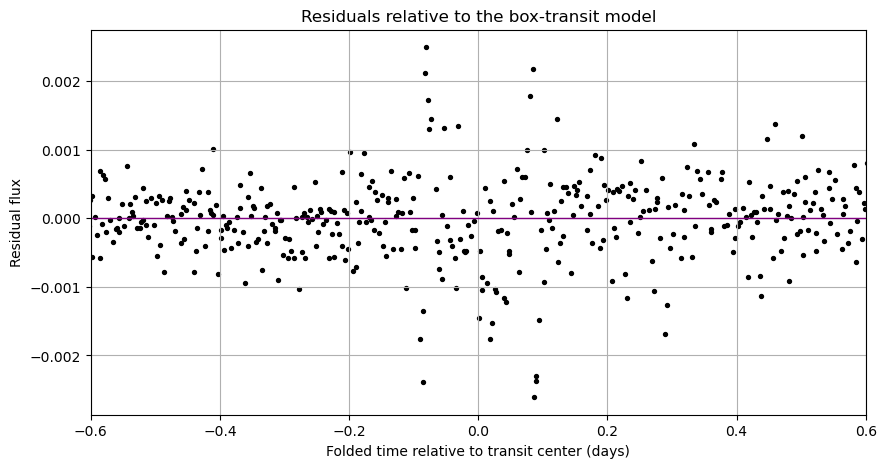

In [34]:
#residual analysis for box model
residuals = flux_norm - box_model_flux

plt.figure()
plt.scatter(phase_box, residuals, s=8, color="black")
plt.axhline(0, color="purple", lw=1)
plt.xlim(-0.6, 0.6)
plt.xlabel("Folded time relative to transit center (days)")
plt.ylabel("Residual flux")
plt.title("Residuals relative to the box-transit model")
plt.show()

## 9. Stellar parameters for TESS B

The host-star parameters are taken from the lab reference table:

- stellar temperature = `6274 ± 97 K`
- stellar radius = `1.925 ± 0.065 R_sun`
- stellar mass = `1.464 ± 0.080 M_sun`

These are used to estimate the planetary radius, orbital distance, orbital speed, transit probability, and equilibrium temperature.

In [35]:
#physical constants in cgs units
G = 6.67430e-8
M_sun = 1.98847e33
R_sun = 6.957e10
R_jup = 7.1492e9
AU = 1.495978707e13

#host star parameters for TESS B
T_star = 6274.0
T_star_err = 97.0

R_star_Rsun = 1.925
R_star_err_Rsun = 0.065

M_star_Msun = 1.464
M_star_err_Msun = 0.080

#adopted measured transit quantities
P_adopt = period_days
P_err = period_err_days

depth_adopt = depth_mean
depth_adopt_err = depth_err

duration_adopt_days = duration_mean_days
duration_adopt_err_days = duration_err_days

## 10. Monte Carlo uncertainty propagation

I used Monte Carlo sampling to see how uncertainty in the transit measurements and stellar parameters affects my calculated results.

For each sample, I recalculated the planet's radius, orbital distance, speed, transit probability, equilibrium temperature, and inclination.

In [36]:
rng = np.random.default_rng(0)
N_mc = 100000

P_samples = rng.normal(P_adopt, P_err, N_mc)
depth_samples = np.clip(rng.normal(depth_adopt, depth_adopt_err, N_mc), 1e-8, None)
duration_samples = np.clip(rng.normal(duration_adopt_days, duration_adopt_err_days, N_mc), 1e-8, None)

R_star_samples = np.clip(rng.normal(R_star_Rsun, R_star_err_Rsun, N_mc), 1e-8, None)
M_star_samples = np.clip(rng.normal(M_star_Msun, M_star_err_Msun, N_mc), 1e-8, None)
T_star_samples = np.clip(rng.normal(T_star, T_star_err, N_mc), 1e-8, None)

P_sec_samples = P_samples * 86400.0
R_star_cm_samples = R_star_samples * R_sun
M_star_g_samples = M_star_samples * M_sun

#planet radius
R_p_cm_samples = np.sqrt(depth_samples) * R_star_cm_samples
R_p_Rj_samples = R_p_cm_samples / R_jup

#semi-major axis from kepler's third law
a_cm_samples = ((G * M_star_g_samples * P_sec_samples**2) / (4.0 * np.pi**2))**(1.0 / 3.0)
a_AU_samples = a_cm_samples / AU

#orbital speed
v_kms_samples = (2.0 * np.pi * a_cm_samples / P_sec_samples) / 1e5

#transit probability (approximation)
transit_probability_samples = R_star_cm_samples / a_cm_samples

#equilibrium temperature with albedo A = 0.4
A = 0.4
T_eq_samples = T_star_samples * np.sqrt(R_star_cm_samples / (2.0 * a_cm_samples)) * (1.0 - A)**0.25

#inclination from transit duration using small-planet circular approximation
x_samples = (duration_samples * 86400.0) * np.pi * a_cm_samples / (P_sec_samples * R_star_cm_samples)
valid = x_samples < 1.0
b_samples = np.sqrt(np.clip(1.0 - x_samples[valid]**2, 0.0, None))
cos_i_samples = np.clip(b_samples * R_star_cm_samples[valid] / a_cm_samples[valid], -1.0, 1.0)
inclination_deg_samples = np.degrees(np.arccos(cos_i_samples))

def summarize(samples):
    return np.mean(samples), np.std(samples, ddof=1)

Rp_Rj, Rp_Rj_err = summarize(R_p_Rj_samples)
a_AU, a_AU_err = summarize(a_AU_samples)
v_kms, v_kms_err = summarize(v_kms_samples)
p_transit, p_transit_err = summarize(transit_probability_samples)
T_eq, T_eq_err = summarize(T_eq_samples)
incl_deg, incl_deg_err = summarize(inclination_deg_samples)

print(f"Planet radius = {Rp_Rj:.3f} ± {Rp_Rj_err:.3f} R_J")
print(f"Semi-major axis = {a_AU:.5f} ± {a_AU_err:.5f} AU")
print(f"Orbital speed = {v_kms:.2f} ± {v_kms_err:.2f} km/s")
print(f"Transit probability = {p_transit:.3f} ± {p_transit_err:.3f}")
print(f"Equilibrium temperature = {T_eq:.0f} ± {T_eq_err:.0f} K")
print(f"Inclination = {incl_deg:.2f} ± {incl_deg_err:.2f} degrees")

Planet radius = 1.422 ± 0.052 R_J
Semi-major axis = 0.06254 ± 0.00114 AU
Orbital speed = 144.07 ± 2.63 km/s
Transit probability = 0.143 ± 0.006
Equilibrium temperature = 1477 ± 36 K
Inclination = 84.87 ± 0.51 degrees


## 11. Orbital Geometry

Using the measured orbital period and semi-major axis, the orbit can be represented as a vector-valued function

$$\mathbf{r}(t) = \langle x(t), y(t) \rangle$$

where

$$x(t) = a \cos(\omega t), \quad y(t) = a \sin(\omega t)$$

and

$$\omega = \frac{2\pi}{P}$$

To model the transit geometry, the orbit is projected onto the sky plane using the estimated inclination.

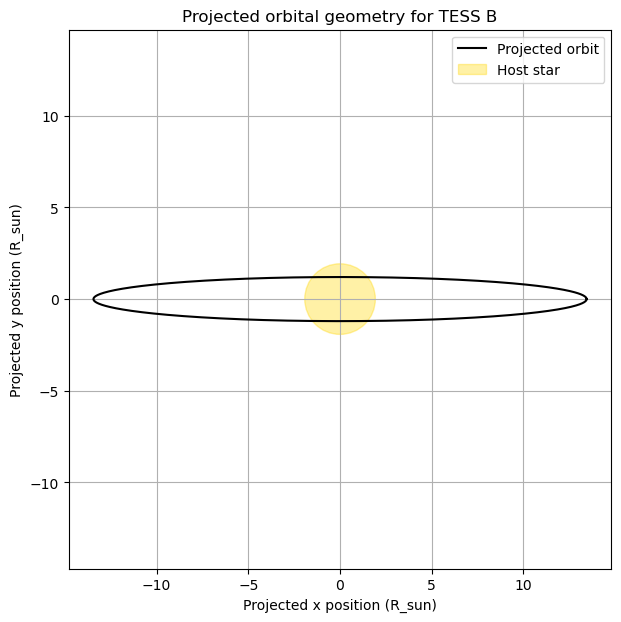

In [37]:
omega = 2.0 * np.pi / P_adopt
a_cm = a_AU * AU
incl_rad = np.radians(incl_deg)

t_orbit_days = np.linspace(0, P_adopt, 1000)
t_orbit_sec = t_orbit_days * 86400.0

x_orbit = a_cm * np.cos(omega * t_orbit_days)
y_orbit = a_cm * np.sin(omega * t_orbit_days)

#projects y-axis by inclination angle
y_projected = y_orbit * np.cos(incl_rad)

projected_separation = np.sqrt(x_orbit**2 + y_projected**2)

plt.figure(figsize=(7, 7))
plt.plot(x_orbit / R_sun, y_projected / R_sun, color="black", label="Projected orbit")
star = plt.Circle((0, 0), R_star_Rsun, color="gold", alpha=0.35, label="Host star")
plt.gca().add_patch(star)
plt.xlabel("Projected x position (R_sun)")
plt.ylabel("Projected y position (R_sun)")
plt.title("Projected orbital geometry for TESS B")
plt.axis("equal")
plt.legend(loc="upper right")
plt.show()

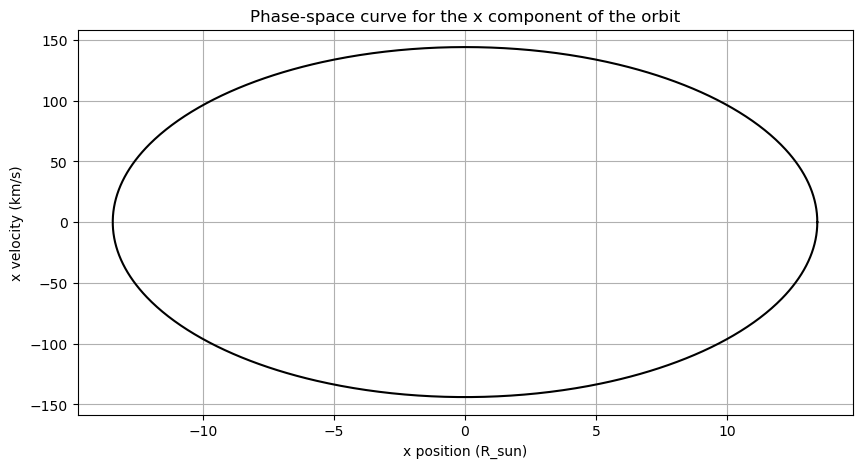

In [38]:
#phase-space style plot for x motion: x versus vx
vx_orbit = -a_cm * omega / 86400.0 * np.sin(omega * t_orbit_days)  #cm/s

plt.figure()
plt.plot(x_orbit / R_sun, vx_orbit / 1e5, color="black")
plt.xlabel("x position (R_sun)")
plt.ylabel("x velocity (km/s)")
plt.title("Phase-space curve for the x component of the orbit")
plt.show()

## 12. Numerical Orbit Simulation Using RK4

Now the same orbit is modeled as a solution to the gravitational system

$$\frac{dx}{dt} = v_x, \quad \frac{dy}{dt} = v_y$$
$$\frac{dv_x}{dt} = -\frac{G M_{\star} x}{r^3}, \quad 
\frac{dv_y}{dt} = -\frac{G M_{\star} y}{r^3}$$

where

$$r = \sqrt{x^2 + y^2}$$

This section numerically integrates the system using a fourth-order Runge-Kutta method.

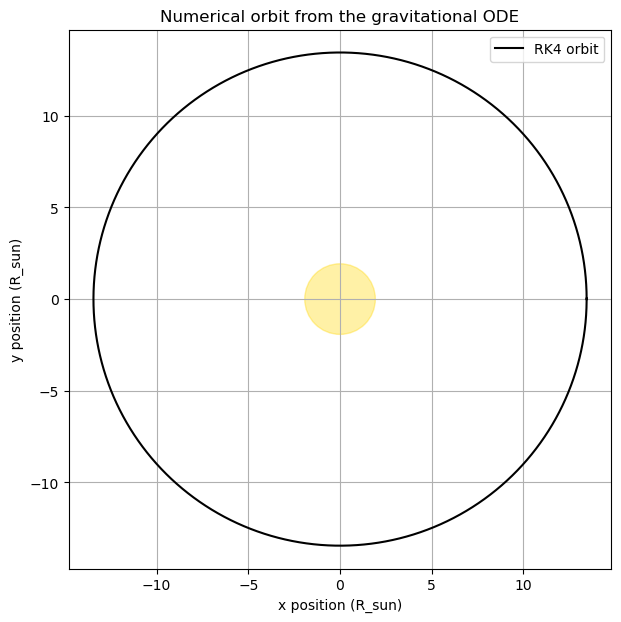

In [39]:
def derivatives(state, M_star_g):
    x, y, vx, vy = state
    r = np.sqrt(x**2 + y**2)
    ax = -G * M_star_g * x / r**3
    ay = -G * M_star_g * y / r**3
    return np.array([vx, vy, ax, ay])


def rk4_step(state, dt, M_star_g):
    k1 = derivatives(state, M_star_g)
    k2 = derivatives(state + 0.5 * dt * k1, M_star_g)
    k3 = derivatives(state + 0.5 * dt * k2, M_star_g)
    k4 = derivatives(state + dt * k3, M_star_g)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)


M_star_g = M_star_Msun * M_sun
P_sec = P_adopt * 86400.0

#initial state for an approximately circular orbit
x0 = a_cm
y0 = 0.0
vx0 = 0.0
vy0 = np.sqrt(G * M_star_g / a_cm)

state = np.array([x0, y0, vx0, vy0], dtype=float)

n_steps = 3000
dt = P_sec / n_steps

states = np.zeros((n_steps + 1, 4))
states[0] = state

for i in range(n_steps):
    state = rk4_step(state, dt, M_star_g)
    states[i + 1] = state

x_num = states[:, 0]
y_num = states[:, 1]

plt.figure(figsize=(7, 7))
plt.plot(x_num / R_sun, y_num / R_sun, color="black", label="RK4 orbit")
star = plt.Circle((0, 0), R_star_Rsun, color="gold", alpha=0.35)
plt.gca().add_patch(star)
plt.xlabel("x position (R_sun)")
plt.ylabel("y position (R_sun)")
plt.title("Numerical orbit from the gravitational ODE")
plt.axis("equal")
plt.legend()
plt.show()

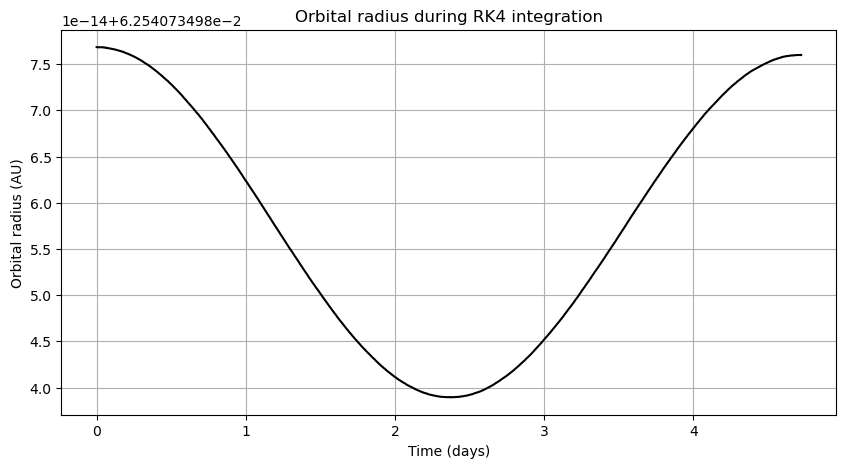

Mean RK4 orbital radius: 0.06254 AU
Standard deviation of RK4 orbital radius: 1.32538e-14 AU


In [40]:
#checks how well numerical orbit conserves radius for circular approximation
r_num = np.sqrt(x_num**2 + y_num**2)

plt.figure()
plt.plot(np.linspace(0, P_adopt, len(r_num)), r_num / AU, color="black")
plt.xlabel("Time (days)")
plt.ylabel("Orbital radius (AU)")
plt.title("Orbital radius during RK4 integration")
plt.show()

print(f"Mean RK4 orbital radius: {np.mean(r_num) / AU:.5f} AU")
print(f"Standard deviation of RK4 orbital radius: {np.std(r_num, ddof=1) / AU:.5e} AU")

## 13. Final results table

In [41]:
results_table = pd.DataFrame({
    "quantity": ["orbital period", "transit depth", "transit duration", "planet radius", "semi-major axis", "orbital speed", "transit probability",
        "equilibrium temperature", "orbital inclination" ],
    "value": [period_days, depth_mean, duration_mean_days * 24.0, Rp_Rj, a_AU, v_kms, p_transit, T_eq, incl_deg],
    "uncertainty": [period_err_days, depth_err, duration_err_days * 24.0, Rp_Rj_err, a_AU_err, v_kms_err, p_transit_err, T_eq_err, incl_deg_err],
    "units": ["days", "fraction", "hours", "R_J", "AU", "km/s", "dimensionless", "K", "degrees" ]})

results_table

,quantity,value,uncertainty,units
0,orbital period,4.722675,0.001883,days
1,transit depth,0.005767,0.000168,fraction
2,transit duration,4.027243,0.025072,hours
3,planet radius,1.422462,0.052388,R_J
4,semi-major axis,0.062541,0.001142,AU
5,orbital speed,144.067719,2.629577,km/s
6,transit probability,0.143187,0.005511,dimensionless
7,equilibrium temperature,1477.210238,36.496265,K
8,orbital inclination,84.870561,0.513165,degrees


## Results and Discussion

The TESS B light curve shows a clear sequence of repeated transits with an orbital period of about 4.72 days.  
Assuming the transit signal comes from a planet, the measured depth gives an estimated radius of 1.42 ± 0.05 Jupiter radii, consistent with a hot-Jupiter-sized candidate. 
The short orbital distance and high estimated equilibrium temperature are also consistent with a close-in giant planet.
The numerical orbit simulation also helped me visualize how the planet's position and velocity change under the star's gravitational influence.


## Limitations and Future Work

The box model does not account for limb darkening or the detailed shape of a transit. The orbital calculations assume a circular orbit, and the inclination calculation uses a simplified approximation. Transit timing and duration measurements may also be affected by noise. Without radial velocity data, I cannot determine the companion's mass or confirm that the signal comes from a planet.

Future work could include fitting a more realistic transit model with limb darkening, improving individual transit timing and duration measurements, and comparing different light-curve normalization methods. Analyzing additional TESS light curves and obtaining radial velocity measurements, if available, could also help characterize the system.

## Conclusion

Through this investigation, I analyzed repeated transits in the TESS B light curve and used the measurements to estimate the properties of a possible exoplanet. I found an orbital period of approximately 4.72 days and a planetary radius of 1.42 ± 0.05 Jupiter radii, consistent with a close-in giant planet candidate.

By combining transit measurements, Monte Carlo uncertainty propagation, orbital geometry, and numerical integration, I was able to connect the observed light curve to the physical behavior of the system. Although the transit data alone cannot confirm the planet or determine its mass, the analysis demonstrates how photometric observations can be used to investigate exoplanetary systems.

---
## Credits & Acknowledgments

**Data Source:** TESS (Transiting Exoplanet Survey Satellite) light-curve observations, provided as `TESSB_lc.dat` through AST 208 coursework.

**Data Provided By:** Dr. Joey Rodriguez, Michigan State University, through AST 208 coursework.

**Academic Background:** This project builds on AST 208 Lab 8, which introduced exoplanet transit analysis using TESS light-curve data.

**Independent Investigation:** I extended the original coursework by implementing automated transit detection, refining individual transit-center measurements, estimating orbital and planetary properties, propagating uncertainties through Monte Carlo sampling, and modeling orbital motion using numerical integration.